# Exercise 7 - Monte Carlo Localization

---

### Required libraries

Please make sure you can import the following libraries before starting:

- NumPy
- OpenCV (cv2)
- Matplotlib
- SciPy

If you are using a custom environment, install missing packages before you begin.

---

### Submission instructions

- Complete **all** tasks in this notebook (code, plots, and written answers).
- Submit **only this completed Jupyter notebook** (`.ipynb`) on teams.
- Do **not** compress it into a `.zip` file or any other archive.
- Make sure every plot has:
  - properly labeled axes,
  - a legend when appropriate,
  - a short explanation (1–3 sentences) interpreting the result.
- Your notebook should run from top to bottom without errors on a clean environment. Dont say: "But prof, it works on my setup."

---

### On tools, integrity, and survival

- Emotional breakdowns are a respected academic tradition, but please maintain **basic fluid‑dynamics control**: if you need to cry, do it *adjacent* to the laptop, not *on* it. Tech, like self‑esteem, can be damaged.
- Using LLMs is allowed, but make sure to use **your own brain**: understand every line of code and every formula you submit. If you cannot explain it, you do not own it.
- Cheating (taking someone else's work) is strictly forbidden. If you’re caught, you will fail the course immediately. More importantly, you’ll have successfully lied to the one person you are stuck with for the rest of your life: yourself. The exam ends in 1h30; your relationship with your own integrity does not.

---

In this assignment you need to implement a particle filter algorithm for localizing a robot in a given map. 
The data for this exercise is recorded on a differential drive robot equipped with a 2D laser scanner that moves in the following environment:

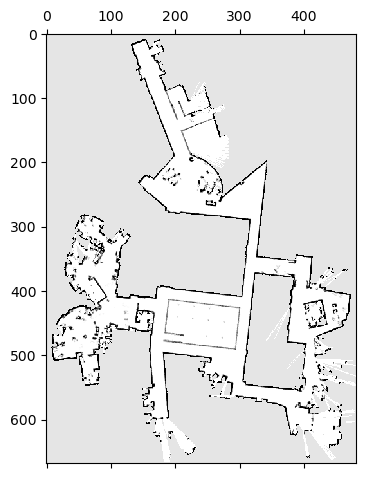

In [2]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import ex7
%matplotlib inline

data = pickle.load(open("dataset_mit_csail.p", "rb"))

plt.matshow(data['img_map'], cmap="gray")
plt.show()

The following data is provided in `data`:

- *img_map* is the image of the environment where the robot must localize
- *likelihood_map* is the likelihood map defined over the environment and used for computing the weights of the particles
- *odom* is the noisy odometry readings observed by the robot during navigation in the form: $\delta_{rot1}, \delta_{trans}, \delta_{rot2}$
- *gt_odom* is the ground truth odometry, you may want to use it for checking your results
- *z* are the laser range measurements (37 beams $\rho_i, \phi_i$) obtained by the robot during navigation, where $\rho_i$ is the range and $\theta_i$ the corresponding firing angle defined wrt the robot orientation

You can access the `data` as follows:

In [ ]:
# get odometry reading at timestep 25
odom_25 = data['odom'][25]
print("Odom at step 25 is: ", odom_25)

# get ground truth odometry reading at timestep 25
odom_gt_25 = data['gt_odom'][25]
print("True odom at step 25 is: ", odom_25)

# get observed scan at timestep 10
z_10 = data['z'][10]
print("Angles at step 10 is: ", z_10[0,:])
print("Ranges at step 10 is: ", z_10[1,:])

Odom at step 25 is:  [ 0.11378333  0.50803543 -0.18586595]
True odom at step 25 is:  [ 0.11378333  0.50803543 -0.18586595]
Angles at step 10 is:  [-1.570796e+00 -1.483526e+00 -1.396256e+00 -1.308986e+00 -1.221716e+00
 -1.134446e+00 -1.047176e+00 -9.599060e-01 -8.726360e-01 -7.853660e-01
 -6.980960e-01 -6.108260e-01 -5.235560e-01 -4.362860e-01 -3.490160e-01
 -2.617460e-01 -1.744760e-01 -8.720600e-02  6.400000e-05  8.733400e-02
  1.746040e-01  2.618740e-01  3.491440e-01  4.364140e-01  5.236840e-01
  6.109540e-01  6.982240e-01  7.854940e-01  8.727640e-01  9.600340e-01
  1.047304e+00  1.134574e+00  1.221844e+00  1.309114e+00  1.396384e+00
  1.483654e+00  1.570924e+00]
Ranges at step 10 is:  [ 3.    2.99  1.33  1.23  1.16  1.14  1.34  1.43  1.4   2.94  3.    3.07
  3.2   3.22  3.59  3.7   3.86  2.75 81.91  1.65  1.68  1.81 81.91 81.91
  4.73  4.76  3.76  4.18  2.3   2.31  5.7   2.33  2.41  4.23  4.09  4.02
 81.91]


## 7.1 Motion update [1.0]

The `sample_motion_model_odometry` function defines the sampling-based odometry motion model. 

This function takes as input:

- the initial pose of the robot $x_{t-1} = [x,y,\theta]$
- the odometry readings $u_t = [\delta_{rot1}, \delta_{trans}, \delta_{rot2}]$ 
- the noise parameters $\mathbf{\alpha} = [0.1, 0.1, 0.1, 0.1]$

The output is a new (sampled) pose predicted by the motion model.

Implement the `sample_motion_model_odometry` function and verify that it is correct for some test input. 

You **can** re-use the your implementation from Exercise 3. 

In [ ]:
def sample_motion_model_odometry(x_prev, u, alpha):
    """
    x_prev: previous pose [x, y, theta]
    u: odometry reading [delta_rot1, delta_trans, delta_rot2]
    alpha: noise parameters [a1, a2, a3, a4]
    """

    x, y, theta = x_prev
    delta_rot1, delta_trans, delta_rot2 = u
    a1, a2, a3, a4 = alpha

    # Compute noise variances
    sigma_rot1 = a1 * delta_rot1**2 + a2 * delta_trans**2
    sigma_trans = a3 * delta_trans**2 + a4 * (delta_rot1**2 + delta_rot2**2)
    sigma_rot2 = a1 * delta_rot2**2 + a2 * delta_trans**2

    # Sample noisy motions
    delta_rot1_hat = delta_rot1 - np.random.normal(0, np.sqrt(sigma_rot1))
    delta_trans_hat = delta_trans - np.random.normal(0, np.sqrt(sigma_trans))
    delta_rot2_hat = delta_rot2 - np.random.normal(0, np.sqrt(sigma_rot2))

    # Predict new pose
    x_new = x + delta_trans_hat * np.cos(theta + delta_rot1_hat)
    y_new = y + delta_trans_hat * np.sin(theta + delta_rot1_hat)
    theta_new = theta + delta_rot1_hat + delta_rot2_hat

    # Normalize angle
    theta_new = np.arctan2(np.sin(theta_new), np.cos(theta_new))

    return np.array([x_new, y_new, theta_new])

In [ ]:
import numpy as np

alpha = [0.1, 0.1, 0.1, 0.1]

x_prev = np.array([2.0, 3.0, np.pi/4])
u = np.array([0.1, 1.0, 0.05])

x_new = sample_motion_model_odometry(x_prev, u, alpha)

print("New sampled pose:", x_new)

New sampled pose: [2.28319484 3.89874657 1.45098237]


## 7.2 Compute weights [3.0]

The `compute_weights` function is responsible for computing the importance weight for each particle according to the observation model, i.e.,

$$w_{i,t} = \eta\,p(z_{t}|x_{i,t}).$$

The motion model is obtained by querying the likelihood map defined over the environment in the endpoints of the laser scan ranges.

The available `ranges2cells` function computes the endpoints of raw scans $(\rho, \phi)$ into map coordinates.

Implement the `compute_weights` function and verify that it is correct for some test input. 

In [3]:
def compute_weights(particles, z, likelihood_map, map_res, map_origin):
    N = particles.shape[0]
    weights = np.zeros(N)

    # Note: Ensure the indexing of z matches your data (usually z['angles'] and z['ranges'])
    # If z is a 2D array passed from data['z'][t]:
    angles = z[0, :]
    ranges = z[1, :]

    for i in range(N):
        pose = particles[i]

        cells = ex7.ranges2cells(ranges, angles, pose, likelihood_map, map_res)

        xs = cells[0, :]
        ys = cells[1, :]

        # Check bounds using the actual map shape
        valid = (
            (xs >= 0) & (xs < likelihood_map.shape[1]) &
            (ys >= 0) & (ys < likelihood_map.shape[0])
        )

        xs = xs[valid].astype(int)
        ys = ys[valid].astype(int)

        if len(xs) == 0:
            weights[i] = -1e10 # Very low log-probability
            continue

        probs = likelihood_map[ys, xs]
        # Avoid log(0)
        probs[probs <= 0] = 1e-9

        weights[i] = np.sum(np.log(probs))

    # Normalize safely
    weights = weights - np.max(weights)
    weights = np.exp(weights)
    weights = weights / (np.sum(weights) + 1e-12)

    return weights

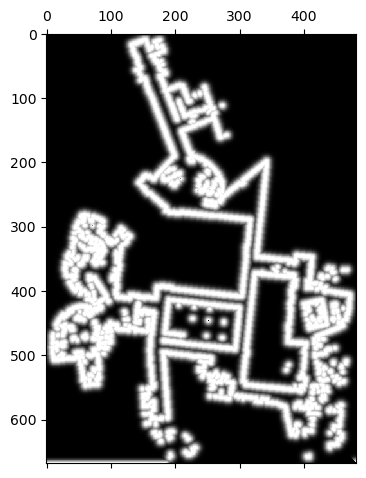

In [ ]:
plt.matshow(data['likelihood_map'], cmap="gray")
plt.show()

## 7.3 Resampling [3.0]

The `resample` function is responsible for re-sampling particles according to their weight (the higher the more likely to be samples) and, thus, “kills” the particles with low weight.

Implement the `resample` function and verify that it is correct for some test input. 

In [ ]:
def resample(particles, weights):
    """
    particles: N x 3 array of particle poses
    weights: N array of normalized weights

    returns:
    new_particles: N x 3 array (resampled particles)
    """

    N = particles.shape[0]
    new_particles = np.zeros_like(particles)

    r = np.random.uniform(0, 1.0 / N)
    c = weights[0]
    i = 0

    for m in range(N):
        U = r + m / N

        while U > c:
            i += 1
            c += weights[i]

        new_particles[m] = particles[i]

    return new_particles

In [ ]:
import numpy as np

particles = np.array([
    [0, 0, 0],
    [1, 1, 0],
    [2, 2, 0]
])

weights = np.array([0.05, 0.9, 0.05])

new_particles = resample(particles, weights)

print(new_particles)

[[1 1 0]
 [1 1 0]
 [1 1 0]]


## 7.4 Localization [3.0]

Once you complete all the above functions, implement the main procedure of Monte Carlo localization `mc_localization` which recursively estimate the position of the robot using the odometry data and the laser scans.

Consider 5000 particles that are intialized uniformly over the environment. 

The map resolution is 0.1 and each particle is a $(x,y,\theta)$ pose.

Plot the belief about the position of the robot after the sequence of odometry readings and laser scans provided in `data` by using the `plot_particles` function.

In [8]:
def mc_localization(data, num_particles, map_res, show_progress=False, progress_every=25):

    # Initialize particles
    particles = ex7.init_uniform(num_particles, data['img_map'], map_res)

    # Keep only x, y, theta
    particles = particles[:, :3]

    alpha = [0.1, 0.1, 0.1, 0.1]

    T = len(data['odom'])

    for t in range(T):

        # 1️⃣ Motion update
        u = data['odom'][t]
        new_particles = np.zeros_like(particles)

        for i in range(num_particles):
            new_particles[i] = ex7.sample_motion_model_odometry(
                particles[i],
                u,
                alpha
            )

        particles = new_particles

        # 2️⃣ Measurement update
        z = data['z'][t]

        weights = ex7.compute_weights(
            particles,
            z,
            data['likelihood_map'],
            map_res,
            data.get('map_origin', [0, 0])
        )

        # 3️⃣ Resampling
        particles = ex7.resample(particles, weights)

        if show_progress and ((t + 1) % progress_every == 0 or t == 0 or t == T - 1):
            print(f"Progress plot at timestep {t+1}/{T}")
            ex7.plot_particles(particles, data['img_map'], map_res)

    return particles

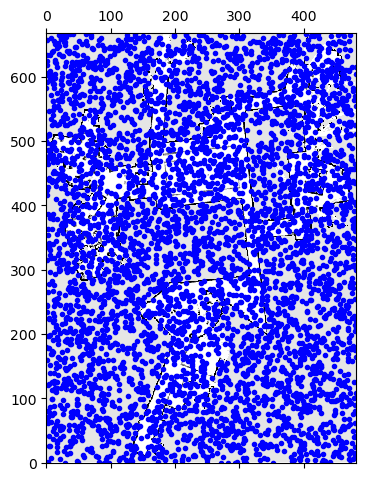

Progress plot at timestep 1/686


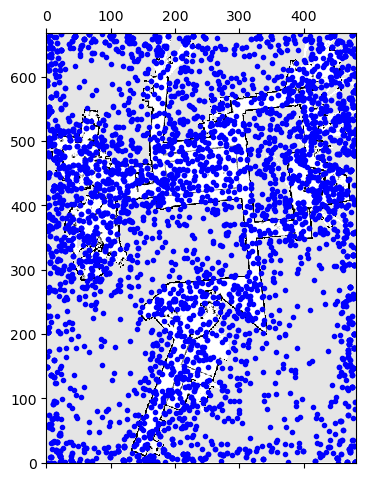

Progress plot at timestep 25/686


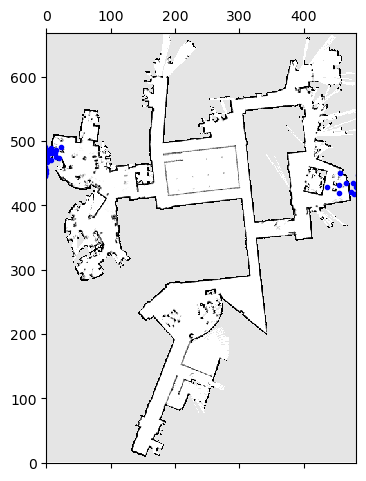

Progress plot at timestep 50/686


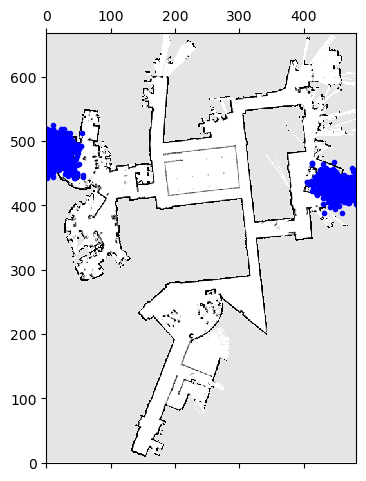

Progress plot at timestep 75/686


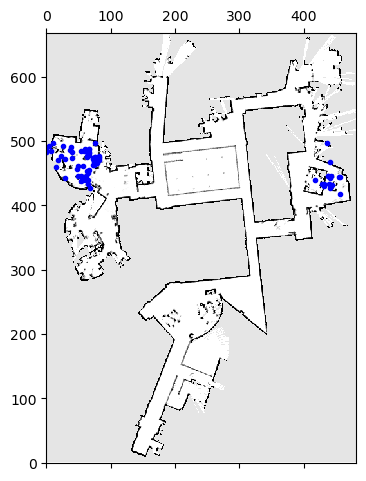

Progress plot at timestep 100/686


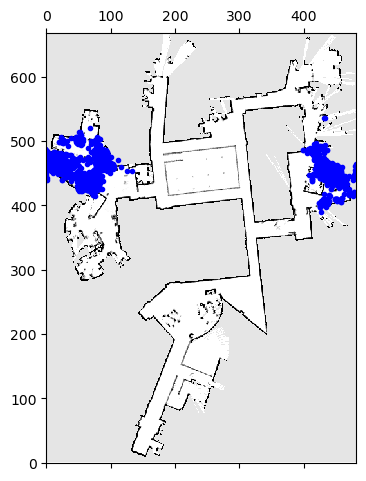

Progress plot at timestep 125/686


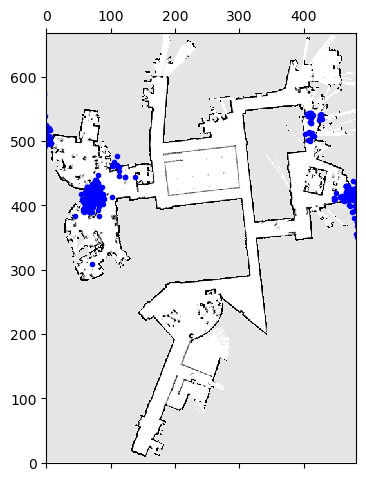

Progress plot at timestep 150/686


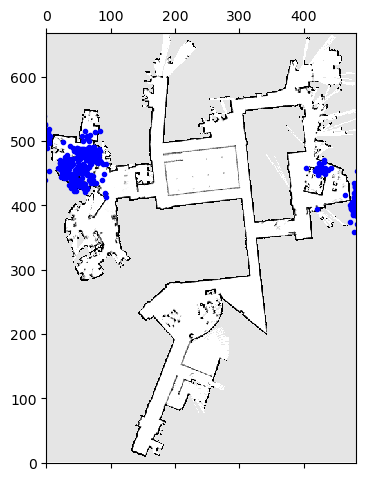

Progress plot at timestep 175/686


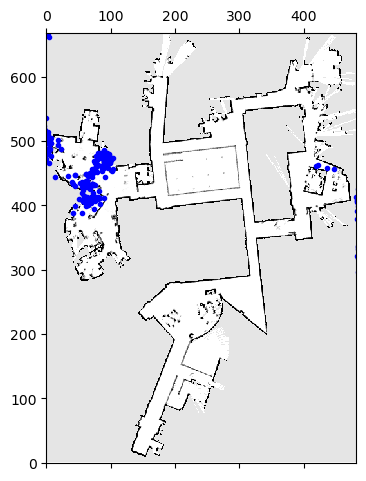

Progress plot at timestep 200/686


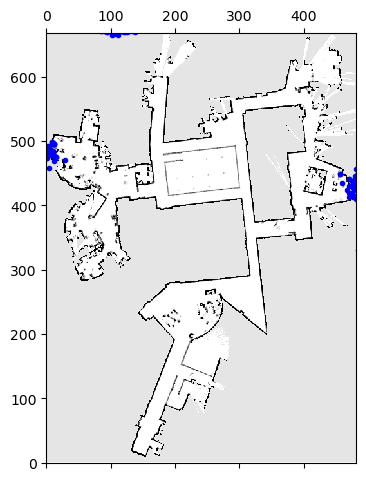

Progress plot at timestep 225/686


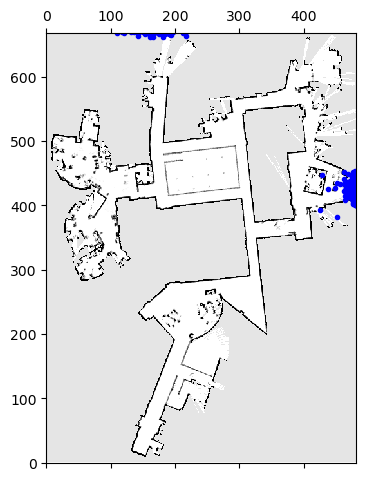

Progress plot at timestep 250/686


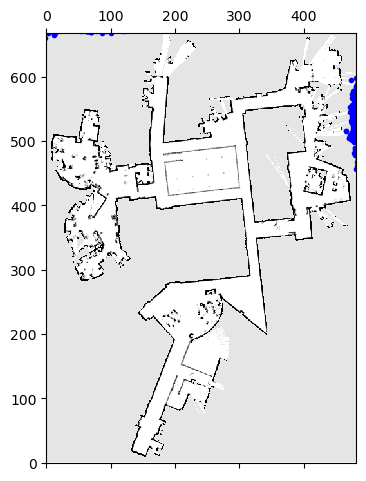

Progress plot at timestep 275/686


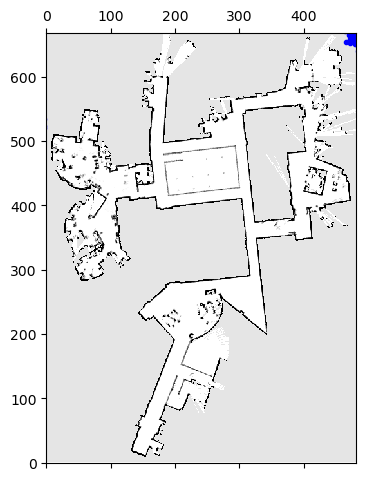

Progress plot at timestep 300/686


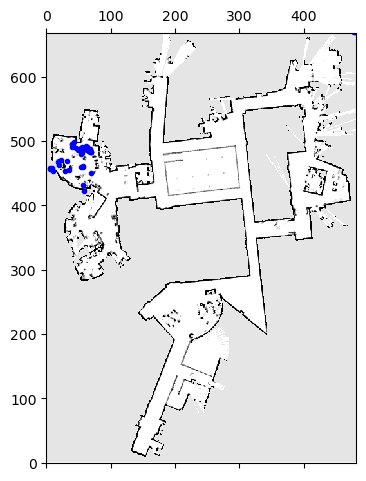

Progress plot at timestep 325/686


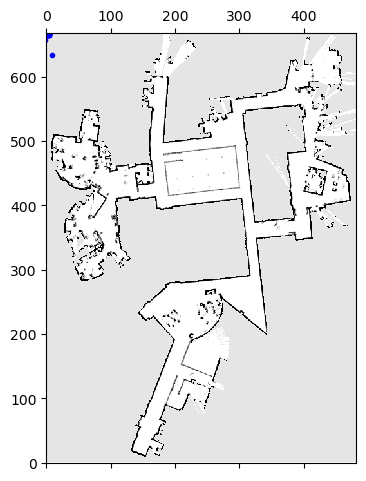

Progress plot at timestep 350/686


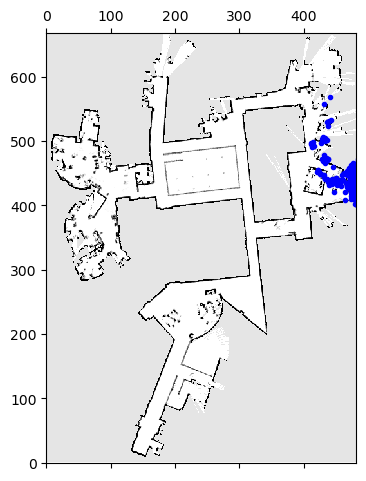

Progress plot at timestep 375/686


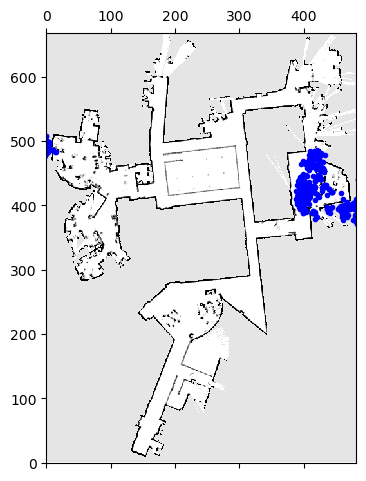

Progress plot at timestep 400/686


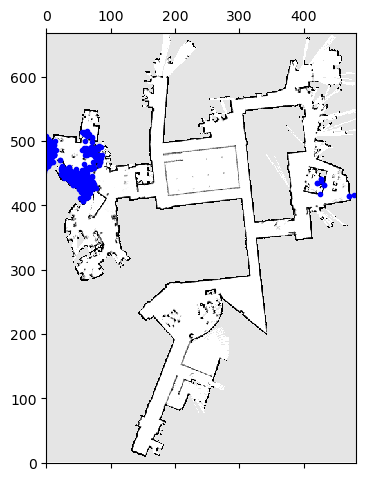

Progress plot at timestep 425/686


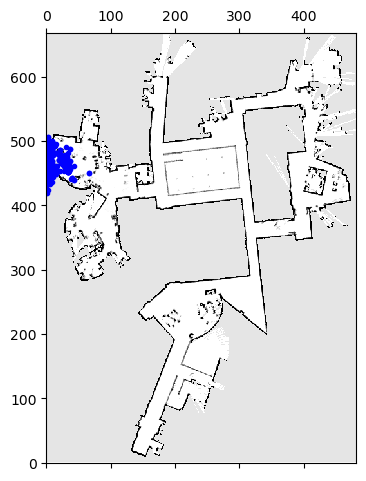

Progress plot at timestep 450/686


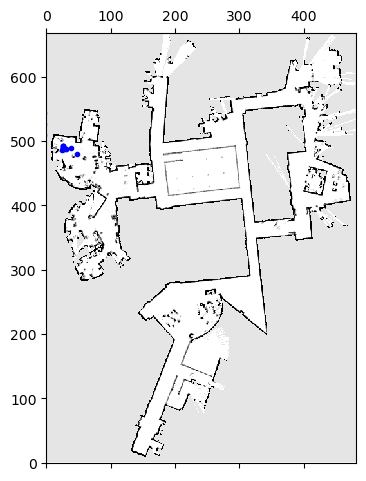

Progress plot at timestep 475/686


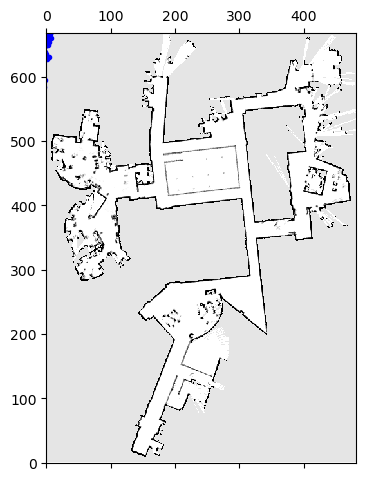

Progress plot at timestep 500/686


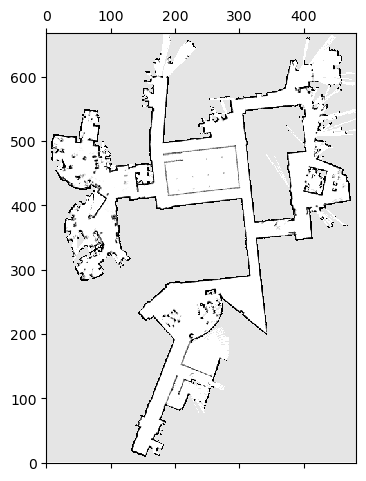

Progress plot at timestep 525/686


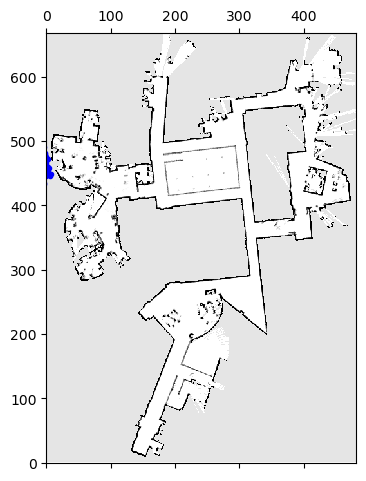

Progress plot at timestep 550/686


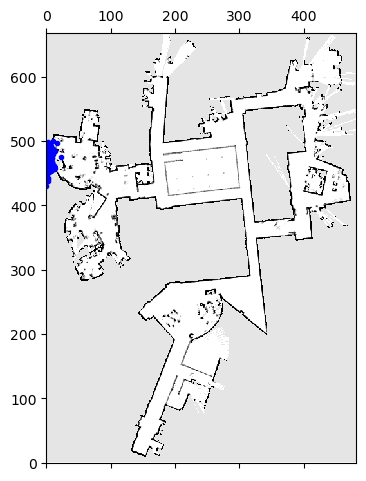

Progress plot at timestep 575/686


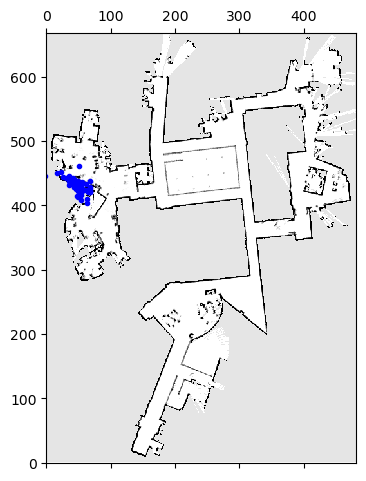

Progress plot at timestep 600/686


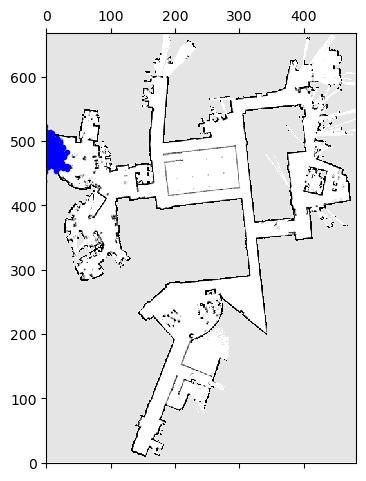

Progress plot at timestep 625/686


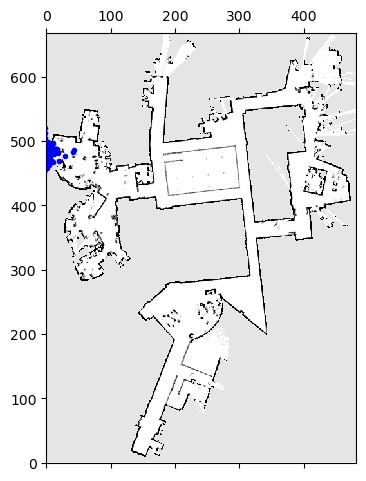

Progress plot at timestep 650/686


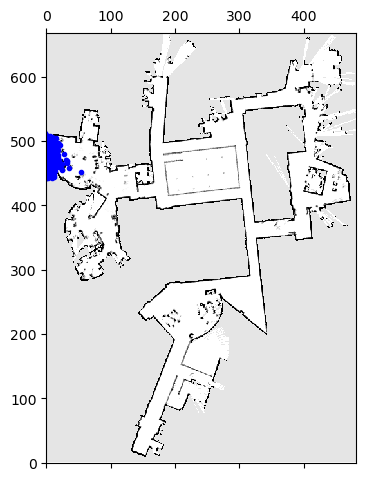

Progress plot at timestep 675/686


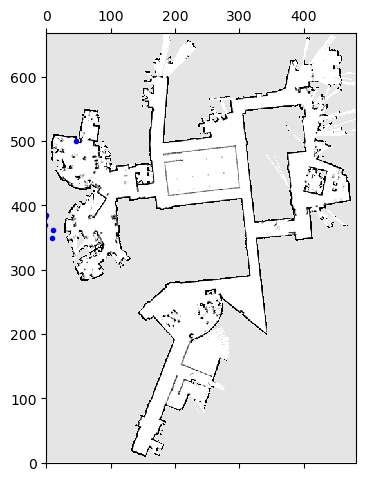

Progress plot at timestep 686/686


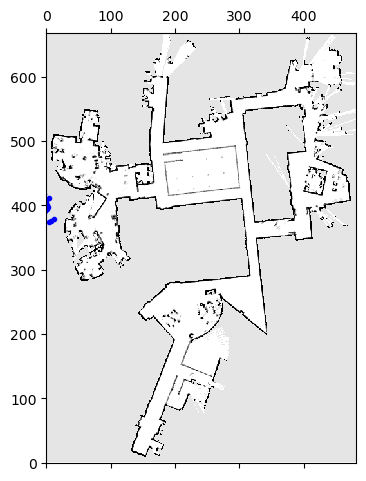

In [9]:
num_particles = 5000
map_res = 0.1

particles = ex7.init_uniform(num_particles, data['img_map'], map_res)
ex7.plot_particles(particles, data['img_map'], map_res)
final_particles = mc_localization(data, num_particles, map_res, show_progress=True, progress_every=25)
